In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    make_scorer
)

from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:


df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


In [4]:
target = "Machine failure"

if target not in df.columns:
    raise ValueError("Machine failure column was not found!")

print("Failure distribution:")
print(df[target].value_counts(dropna=False))

print("\nFailure percentage:")
print(df[target].value_counts(normalize=True, dropna=False) * 100)

Failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [5]:
df = df.copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

print("Column names cleaned.")
print(df.columns.tolist())

Column names cleaned.
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


C:\Users\Sakshi Singh\AppData\Local\Temp\ipykernel_29452\889010893.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total missing values: 0


In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

# Remove only completely identical rows
df = df.drop_duplicates().copy()

print("Shape after removing exact duplicates:", df.shape)

Exact duplicate rows: 0
Shape after removing exact duplicates: (10000, 14)


In [8]:
identifier_columns = ["UDI", "Product ID"]

for column in identifier_columns:
    if column in df.columns:
        print(column, "unique values:", df[column].nunique())

UDI unique values: 10000
Product ID unique values: 10000


In [9]:
print("Target values before cleaning:")
print(df[target].value_counts(dropna=False))

# Convert the target to numeric
df[target] = pd.to_numeric(df[target], errors="coerce")

# Remove rows where the target is missing
df = df.dropna(subset=[target]).copy()

# Keep only valid binary target values: 0 or 1
df = df[df[target].isin([0, 1])].copy()

# Convert target to integer
df[target] = df[target].astype(int)

print("\nTarget values after cleaning:")
print(df[target].value_counts())

print("\nCleaned dataset shape:", df.shape)

Target values before cleaning:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Target values after cleaning:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Cleaned dataset shape: (10000, 14)


In [10]:
input_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

excluded_columns = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

# Check that all required features exist
missing_features = [
    column for column in input_features
    if column not in df.columns
]

if missing_features:
    raise ValueError(
        f"These input features are missing: {missing_features}"
    )

# Check the target and features for data types
print(df[input_features + [target]].dtypes)

Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
dtype: object


In [11]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Convert numeric features to numeric values
for column in numeric_features:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Check for invalid numeric values
print("Missing values after numeric conversion:")
print(df[input_features].isnull().sum())

print("\nNumeric feature summary:")
display(df[numeric_features].describe().T)

Missing values after numeric conversion:
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64

Numeric feature summary:


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


In [12]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df[input_features + [target]].isnull().sum())

print("\nTarget distribution:")
print(df[target].value_counts())

print("\nTarget percentages:")
print(
    (df[target].value_counts(normalize=True) * 100).round(2)
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSelected input features:")
print(input_features)

print("\nExcluded columns:")
print(excluded_columns)

Final dataset shape: (10000, 14)

Missing values:
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
dtype: int64

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Target percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Duplicate rows: 0

Selected input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Excluded columns:
['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


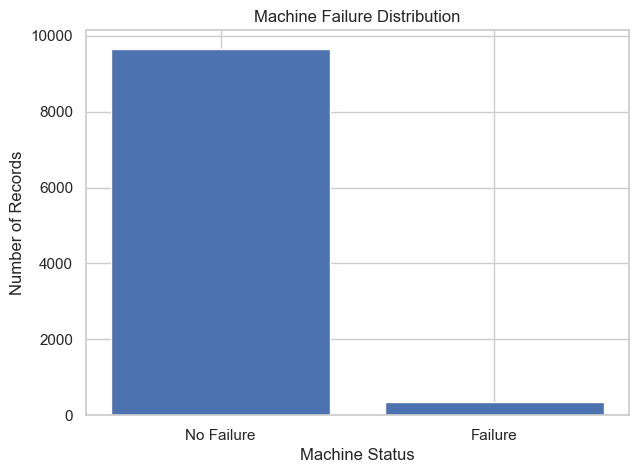

In [13]:
failure_counts = df[target].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Failure", "Failure"],
    [failure_counts.get(0, 0), failure_counts.get(1, 0)]
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Status")
plt.ylabel("Number of Records")
plt.show()

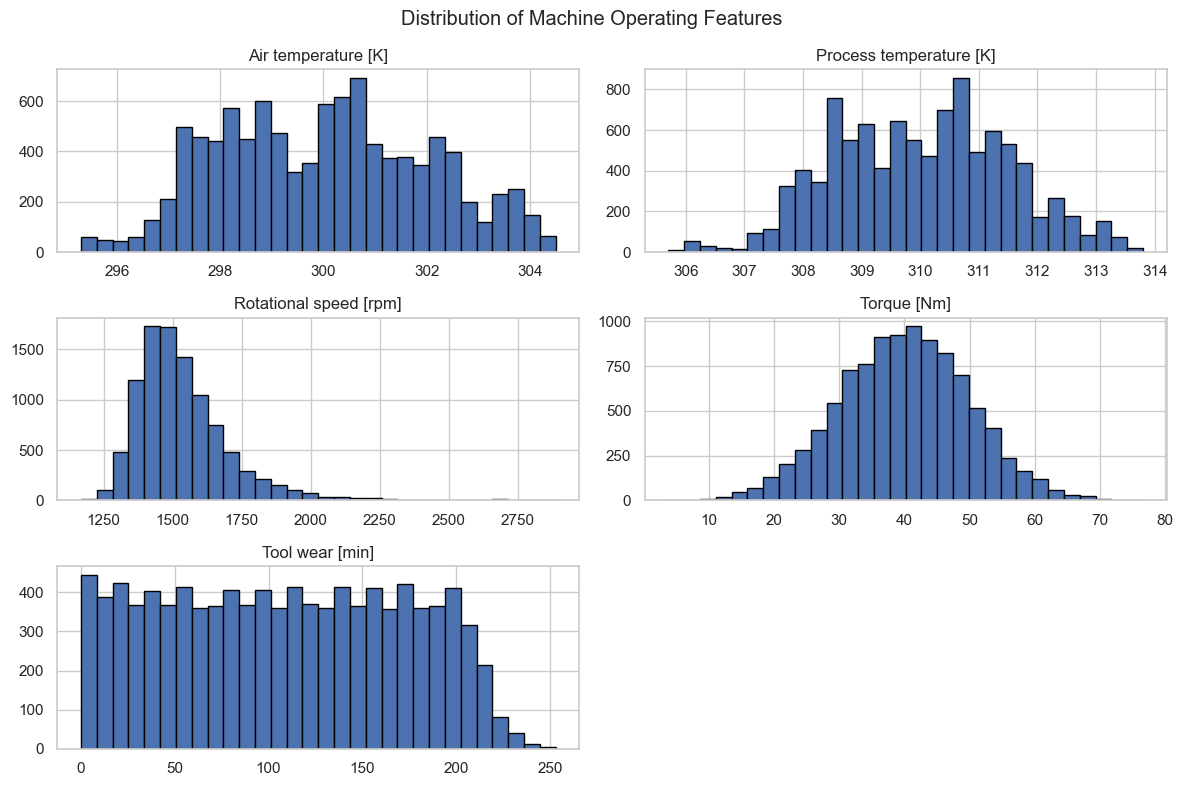

In [14]:
df[numeric_features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Machine Operating Features")
plt.tight_layout()
plt.show()

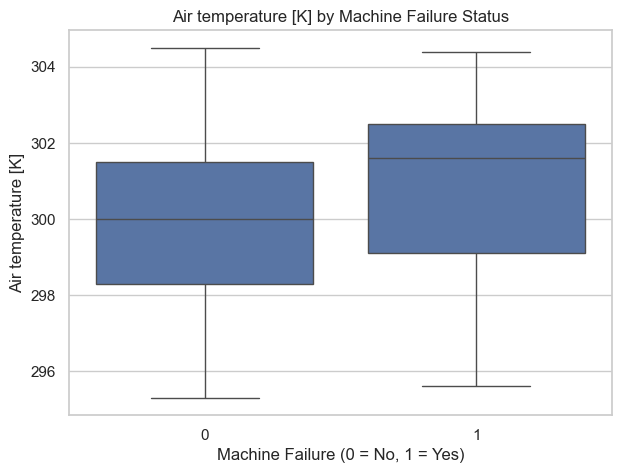

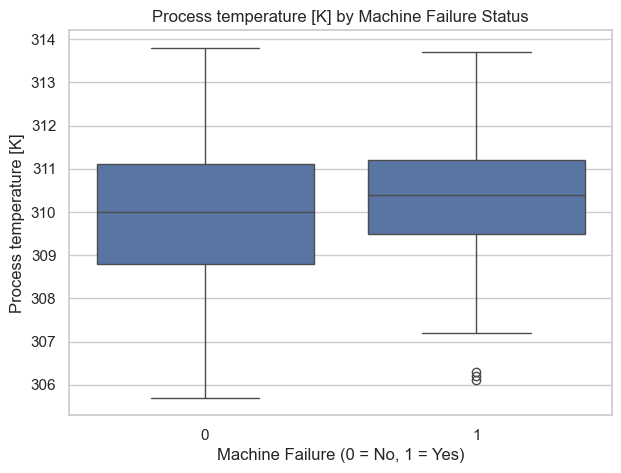

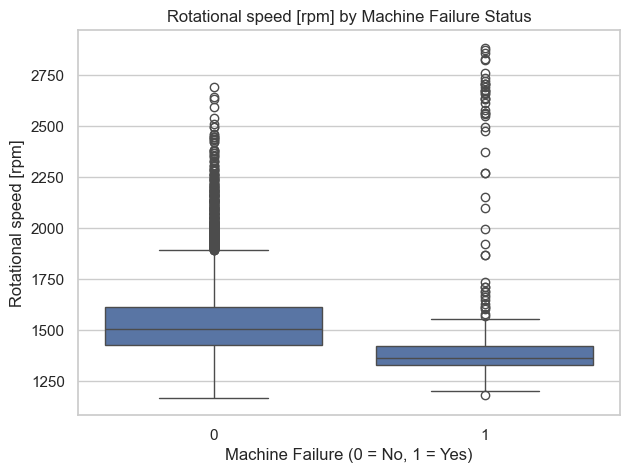

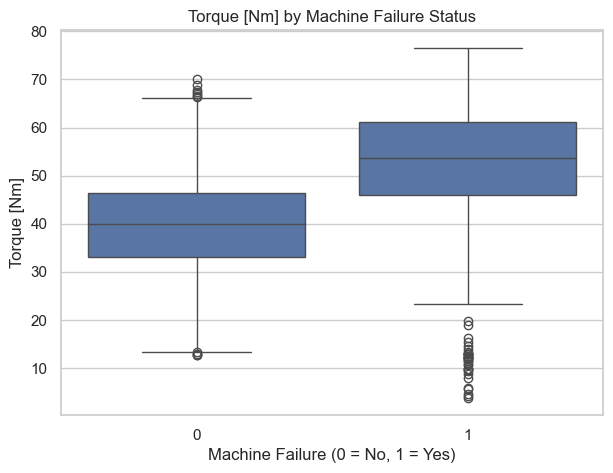

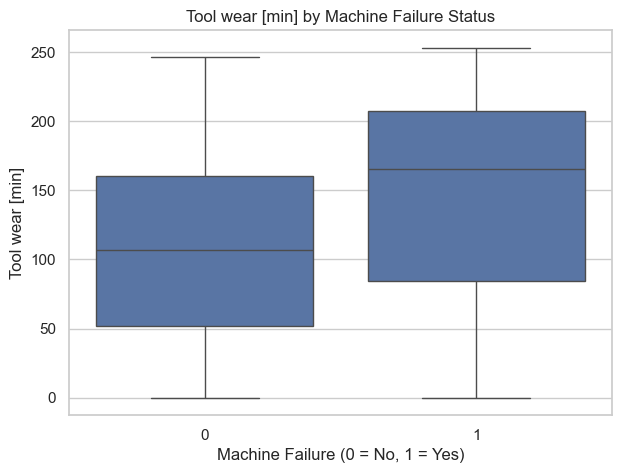

In [15]:
for column in numeric_features:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=target,
        y=column
    )

    plt.title(f"{column} by Machine Failure Status")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(column)
    plt.show()

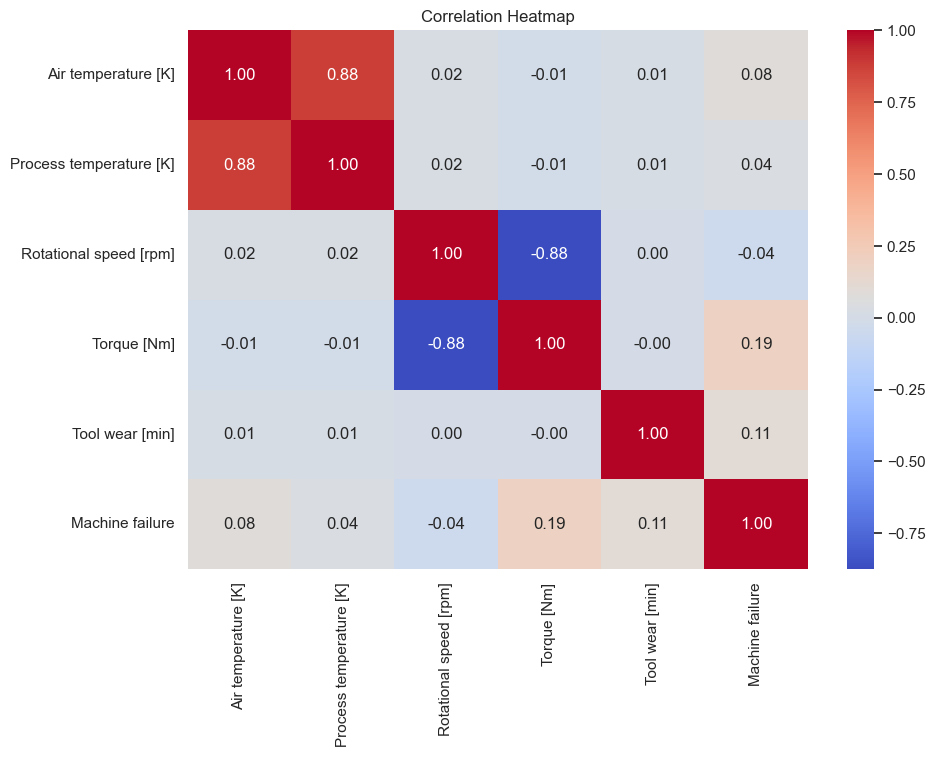

In [16]:
plt.figure(figsize=(10, 7))

correlation = df[numeric_features + [target]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [17]:
X = df[input_features].copy()
y = df[target].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget values:")
display(y.head())

Input shape: (10000, 6)
Target shape: (10000,)

Input features:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9



Target values:


0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining failure rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting failure rate:")
print(round(y_test.mean() * 100, 2), "%")

Training records: 8000
Testing records: 2000

Training failure rate:
3.39 %

Testing failure rate:
3.4 %


In [19]:
categorical_features = ["Type"]

# Process categorical values
categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Process numeric values
numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_preprocessing, categorical_features),
        ("numeric", numeric_preprocessing, numeric_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [20]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(50, 25),
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
}

pipelines = {}

for model_name, classifier in models.items():
    pipelines[model_name] = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

print("Created", len(pipelines), "model pipelines.")

Created 7 model pipelines.


In [21]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Five-fold stratified cross-validation is ready.")

Five-fold stratified cross-validation is ready.


In [22]:
cv_results = []

for model_name, pipeline in pipelines.items():
    print("Training and evaluating:", model_name)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1
    )

    cv_results.append({
        "Model": model_name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(
    cv_results_df.round(4)
)

Training and evaluating: Logistic Regression
Training and evaluating: Decision Tree
Training and evaluating: SVM
Training and evaluating: Random Forest
Training and evaluating: KNN
Training and evaluating: Naive Bayes
Training and evaluating: MLP Neural Network


,Model,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.7036,0.5719,0.6283,0.7817
1,Random Forest,0.9112,0.3653,0.5204,0.9660
2,KNN,0.7949,0.3174,0.4522,0.8471
3,MLP Neural Network,0.7800,0.3285,0.4320,0.9355
4,SVM,0.2783,0.8670,0.4210,0.9602
5,Naive Bayes,0.3642,0.2399,0.2887,0.8622
6,Logistic Regression,0.1374,0.8044,0.2346,0.8965


<Figure size 1000x600 with 0 Axes>

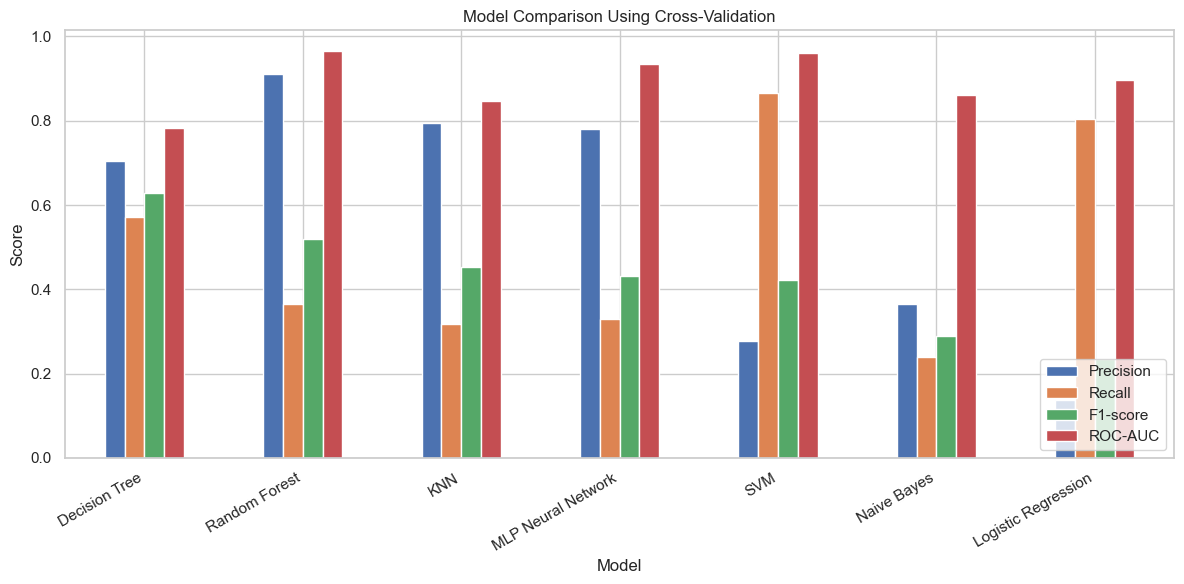

In [23]:
plt.figure(figsize=(10, 6))

cv_results_df.set_index("Model")[
    ["Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Model Comparison Using Cross-Validation")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [24]:
best_model_name = cv_results_df.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]

print("Selected model:", best_model_name)
print(
    "Cross-validation F1-score:",
    round(cv_results_df.iloc[0]["F1-score"], 4)
)
print(
    "Cross-validation recall:",
    round(cv_results_df.iloc[0]["Recall"], 4)
)

Selected model: Decision Tree
Cross-validation F1-score: 0.6283
Cross-validation recall: 0.5719


In [25]:
oof_probabilities = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Out-of-fold probabilities generated.")
print("Number of predictions:", len(oof_probabilities))

Out-of-fold probabilities generated.
Number of predictions: 8000


In [26]:
threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):
    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_train,
        oof_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        oof_predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_train,
        oof_predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

# Prefer thresholds with at least 70% recall
acceptable_thresholds = threshold_df[
    threshold_df["Recall"] >= 0.70
]

if not acceptable_thresholds.empty:
    selected_threshold_row = acceptable_thresholds.loc[
        acceptable_thresholds["F1-score"].idxmax()
    ]
else:
    # If the recall target cannot be met, choose the best F1-score
    selected_threshold_row = threshold_df.loc[
        threshold_df["F1-score"].idxmax()
    ]

best_threshold = float(
    selected_threshold_row["Threshold"]
)

print("Selected threshold:", round(best_threshold, 2))
print(
    "Training OOF precision:",
    round(selected_threshold_row["Precision"], 4)
)
print(
    "Training OOF recall:",
    round(selected_threshold_row["Recall"], 4)
)
print(
    "Training OOF F1-score:",
    round(selected_threshold_row["F1-score"], 4)
)

Selected threshold: 0.05
Training OOF precision: 0.7014
Training OOF recall: 0.572
Training OOF F1-score: 0.6301


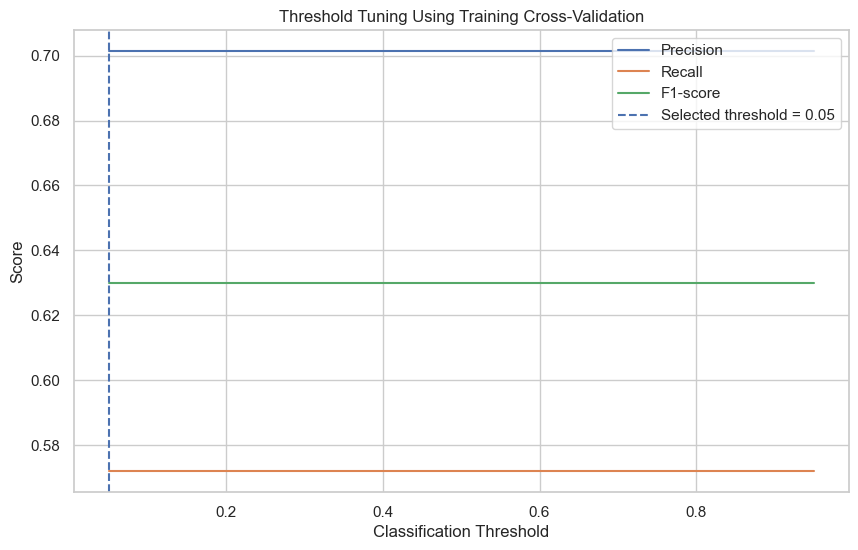

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    label="F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Tuning Using Training Cross-Validation")
plt.legend()
plt.show()

In [28]:
best_pipeline.fit(X_train, y_train)

print("Final model trained successfully!")
print("Model:", best_model_name)

Final model trained successfully!
Model: Decision Tree


In [29]:
test_probabilities = best_pipeline.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Test predictions generated.")
print("Test records:", len(test_predictions))

Test predictions generated.
Test records: 2000


In [30]:
test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

final_results = pd.DataFrame([{
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1-score": test_f1,
    "ROC-AUC": test_roc_auc
}])

display(final_results.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.05,0.978,0.7143,0.5882,0.6452,0.79


In [31]:
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.71      0.59      0.65        68

    accuracy                           0.98      2000
   macro avg       0.85      0.79      0.82      2000
weighted avg       0.98      0.98      0.98      2000



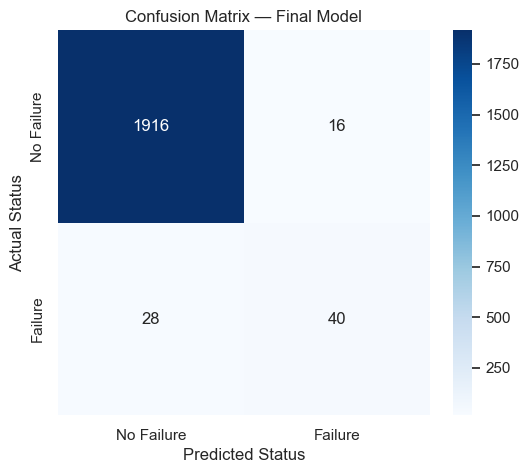

True negatives: 1916
False positives: 16
False negatives: 28
True positives: 40


In [32]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.title("Confusion Matrix — Final Model")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

In [33]:
importance_result = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": input_features,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Importance,Std
0,Rotational speed [rpm],0.1456,0.0177
1,Torque [Nm],0.1118,0.0165
2,Air temperature [K],0.0960,0.0169
3,Tool wear [min],0.0492,0.0115
4,Type,0.0203,0.0088
5,Process temperature [K],-0.0105,0.0169


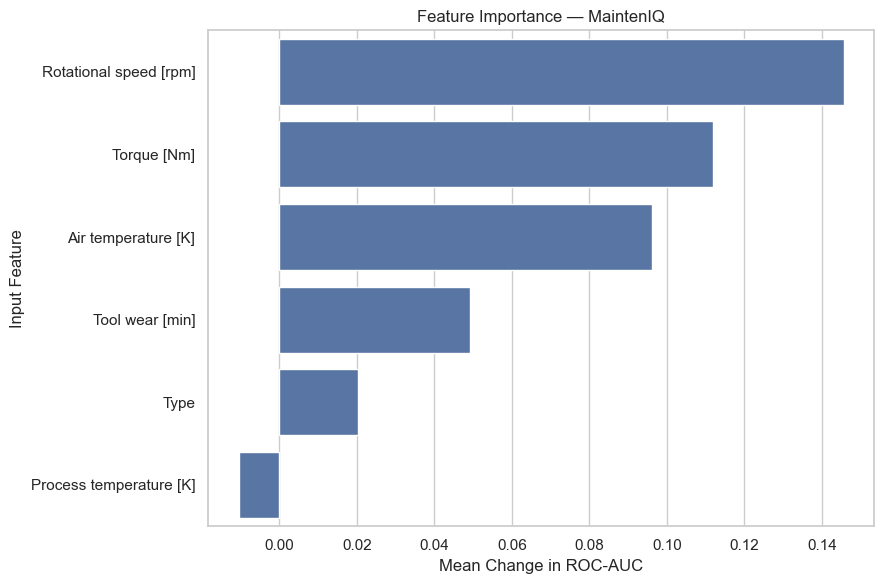

In [34]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance — MaintenIQ")
plt.xlabel("Mean Change in ROC-AUC")
plt.ylabel("Input Feature")
plt.tight_layout()
plt.show()

In [37]:
from pathlib import Path

# The 'r' before the string prevents the escape sequence warning
model_dir = Path(r"D:\My Projects\MaintenIQ Project\model")
model_dir.mkdir(parents=True, exist_ok=True)

print("Model folder:", model_dir.resolve())

Model folder: D:\My Projects\MaintenIQ Project\model


In [38]:
model_path = model_dir / "mainteniq_pipeline.joblib"

joblib.dump(best_pipeline, model_path)

print("Trained pipeline saved successfully!")
print("Saved at:", model_path.resolve())

Trained pipeline saved successfully!
Saved at: D:\My Projects\MaintenIQ Project\model\mainteniq_pipeline.joblib


In [39]:
metadata = {
    "project": "MaintenIQ",
    "target": target,
    "input_features": input_features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "excluded_features": [
        column for column in excluded_columns
        if column in df.columns
    ],
    "model_name": best_model_name,
    "classification_threshold": best_threshold,
    "test_metrics": {
        "accuracy": float(test_accuracy),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f1_score": float(test_f1),
        "roc_auc": float(test_roc_auc)
    }
}

metadata_path = model_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved successfully!")
print("Saved at:", metadata_path.resolve())

Metadata saved successfully!
Saved at: D:\My Projects\MaintenIQ Project\model\model_metadata.json


In [40]:
loaded_pipeline = joblib.load(model_path)

with open(metadata_path, "r", encoding="utf-8") as file:
    loaded_metadata = json.load(file)

print("Model loaded successfully!")
print("Loaded model:", loaded_metadata["model_name"])
print(
    "Loaded threshold:",
    loaded_metadata["classification_threshold"]
)

Model loaded successfully!
Loaded model: Decision Tree
Loaded threshold: 0.05


In [41]:
# Select five test records
sample_data = X_test.head(5)

# Predictions from the original fitted pipeline
original_probabilities = best_pipeline.predict_proba(
    sample_data
)[:, 1]

# Predictions from the saved and reloaded pipeline
loaded_probabilities = loaded_pipeline.predict_proba(
    sample_data
)[:, 1]

# Check that both versions produce the same probabilities
if np.allclose(
    original_probabilities,
    loaded_probabilities
):
    print("Integration test passed!")
    print("Original and reloaded predictions match.")
else:
    print("Integration test failed!")

Integration test passed!
Original and reloaded predictions match.


In [42]:
threshold = loaded_metadata["classification_threshold"]

sample_predictions = (
    loaded_probabilities >= threshold
).astype(int)

prediction_results = sample_data.copy()

prediction_results["Actual Failure"] = y_test.loc[
    sample_data.index
]

prediction_results["Failure Probability"] = (
    loaded_probabilities.round(4)
)

prediction_results["Predicted Failure"] = sample_predictions

prediction_results["Predicted Status"] = np.where(
    sample_predictions == 1,
    "Failure Risk Detected",
    "No Failure Risk Detected"
)

display(prediction_results)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Actual Failure,Failure Probability,Predicted Failure,Predicted Status
2997,L,300.5,309.8,1345,62.7,153,0,0.0,0,No Failure Risk Detected
4871,L,303.7,312.4,1513,40.1,135,0,0.0,0,No Failure Risk Detected
3858,L,302.5,311.4,1559,37.6,209,0,0.0,0,No Failure Risk Detected
951,H,295.6,306.3,1509,35.8,60,0,0.0,0,No Failure Risk Detected
6463,H,300.5,310.0,1358,60.4,102,0,0.0,0,No Failure Risk Detected


## 11. Multi-Label Failure Diagnostics Model

In addition to predicting general machine failure, we build a dedicated **multi-label diagnostic model**.
The dataset provides 5 failure modes:
- **TWF**: Tool Wear Failure
- **HDF**: Heat Dissipation Failure
- **PWF**: Power Failure
- **OSF**: Overstrain Failure
- **RNF**: Random Failure

> **Methodology & Constraints**:
> 1. The binary machine failure classifier is kept separate and untouched.
> 2. Only the six valid operating condition features (`Type`, `Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]`) are used as inputs.
> 3. Failure-mode labels are used **only** as targets for the diagnostic model, never as inputs.
> 4. A `MultiOutputClassifier` wrapping `RandomForestClassifier` is employed with balanced class weights to support multiple co-occurring failure modes.

In [ ]:
import numpy as np
import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, hamming_loss, f1_score, precision_recall_fscore_support

target_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Y_diag = df[target_modes]

# Train-test split (80/20 with random_state=42)
X_train_d, X_test_d, Y_train_d, Y_test_d = train_test_split(
    X, Y_diag, test_size=0.2, random_state=42
)

diag_rf = RandomForestClassifier(n_estimators=120, class_weight='balanced', random_state=42, n_jobs=-1)
diag_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', MultiOutputClassifier(diag_rf))
])

diag_pipeline.fit(X_train_d, Y_train_d)
print('Multi-label diagnostic model trained successfully!')


### Evaluation & Comparison against Baselines
We evaluate multi-label performance using Exact Match Accuracy, Hamming Loss, Micro/Macro F1-score, and per-label precision/recall.

In [ ]:
probs_d = diag_pipeline.predict_proba(X_test_d)
thresholds = {'TWF': 0.15, 'HDF': 0.35, 'PWF': 0.20, 'OSF': 0.35, 'RNF': 0.50}

Y_pred_d = np.zeros_like(Y_test_d.values)
print('Per-label diagnostic metrics on test set:')
for idx, lbl in enumerate(target_modes):
    p_col = probs_d[idx][:, 1]
    th = thresholds[lbl]
    pred_col = (p_col >= th).astype(int)
    Y_pred_d[:, idx] = pred_col
    prec, rec, f1, sup = precision_recall_fscore_support(Y_test_d.iloc[:, idx], pred_col, average='binary', zero_division=0)
    print(f'{lbl:4s} -> Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f} (Support: {sup})')

print(f'Exact Match Accuracy: {accuracy_score(Y_test_d, Y_pred_d):.4f}')
print(f'Hamming Loss: {hamming_loss(Y_test_d, Y_pred_d):.4f}')
print(f'Micro F1: {f1_score(Y_test_d, Y_pred_d, average="micro"):.4f}')
print(f'Macro F1: {f1_score(Y_test_d, Y_pred_d, average="macro"):.4f}')


### Exporting Diagnostic Pipeline
We export the diagnostic pipeline as an independent artifact `model/mainteniq_diagnostics_pipeline.joblib`.

In [ ]:
diag_model_path = model_dir / 'mainteniq_diagnostics_pipeline.joblib'
joblib.dump(diag_pipeline, diag_model_path)
print('Diagnostic pipeline saved at:', diag_model_path.resolve())
